But de ce notebook: préparer les données Météo Synop pour être merger avec le reste des données qui permettra de tester et entrainer les modèles de Maching Learning

Sur les années 2021-2024, granusolité à la semaine et code département

1. Concatener les fichiers de pour n'avoir qu'un fichier de travail pour l'exploration de données

Je suis en présence de 6 fichiers allant de l'année 2021 à 2026 (1 par année) mais il a été décidé de se concentré sur les années 2021-2024 car c'est les années les plus complète que nous avaons sur l'ensemble des données

In [108]:
#import librairie nécessaire
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [109]:
import glob
# Lister tous les fichiers météo dans l'ordre des années
fichiers_meteo = sorted(glob.glob("../data/raw/Synop Meteo/synop_*.csv.gz"))

# Charger et concaténer
df_meteo = pd.concat(
    [pd.read_csv(f, compression='gzip', sep=';') for f in fichiers_meteo], 
    ignore_index=True)

#Vérifier l'importation'
display(df_meteo.head(15))

display(df_meteo.shape)

,lat,lon,geo_id_wmo,geo_id_wigos,name,reference_time,insert_time,validity_time,pmer,tend,...,hnuage1,nnuage2,ctype2,hnuage2,nnuage3,ctype3,hnuage3,nnuage4,ctype4,hnuage4
0,50.136000,1.834000,7005,0-20000-0-07005,ABBEVILLE,NaN,NaN,2021-01-01T00:00:00Z,100830.0,80.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,43.648833,7.209000,7690,0-20000-0-07690,NICE,NaN,NaN,2021-01-01T00:00:00Z,100820.0,-90.0,...,1000.0,7.0,6.0,1800.0,NaN,NaN,NaN,NaN,NaN,NaN
2,47.444500,0.727333,7240,0-20000-0-07240,TOURS,NaN,NaN,2021-01-01T00:00:00Z,100800.0,40.0,...,1470.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,-20.892167,55.528667,61980,0-20000-0-61980,GILLOT-AEROPORT,NaN,NaN,2021-01-01T00:00:00Z,101490.0,-80.0,...,840.0,3.0,NaN,1440.0,7.0,NaN,1680.0,NaN,9.0,NaN
4,47.059167,2.359833,7255,0-20000-0-07255,BOURGES,NaN,NaN,2021-01-01T00:00:00Z,100860.0,70.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,43.437667,5.216000,7650,0-20000-0-07650,MARIGNANE,NaN,NaN,2021-01-01T00:00:00Z,100550.0,-210.0,...,1020.0,5.0,NaN,1410.0,6.0,NaN,1680.0,NaN,8.0,NaN
6,-11.582667,47.289667,61968,0-20000-0-61968,GLORIEUSES,NaN,NaN,2021-01-01T00:00:00Z,100970.0,70.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,48.718000,2.397000,7149,0-20000-0-07149,ORLY,NaN,NaN,2021-01-01T00:00:00Z,100810.0,80.0,...,600.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,48.324667,4.020000,7168,0-20000-0-07168,TROYES-BARBEREY,NaN,NaN,2021-01-01T00:00:00Z,100750.0,80.0,...,570.0,8.0,NaN,1320.0,NaN,NaN,NaN,NaN,NaN,NaN
9,4.822333,-52.365333,81405,0-20000-0-81405,CAYENNE-MATOURY,NaN,NaN,2021-01-01T00:00:00Z,101250.0,160.0,...,540.0,6.0,NaN,780.0,8.0,NaN,1680.0,NaN,8.0,NaN


(675000, 65)

In [110]:
# verifier que toutes les années sont présentes
annees_disponibles = df_meteo['validity_time'].unique()
display(annees_disponibles)

<StringArray>
['2021-01-01T00:00:00Z', '2021-01-01T03:00:00Z', '2021-01-01T06:00:00Z',
 '2021-01-01T09:00:00Z', '2021-01-01T12:00:00Z', '2021-01-01T15:00:00Z',
 '2021-01-01T18:00:00Z', '2021-01-01T21:00:00Z', '2021-01-02T00:00:00Z',
 '2021-01-02T03:00:00Z',
 ...
 '2024-12-30T18:00:00Z', '2024-12-30T21:00:00Z', '2024-12-31T00:00:00Z',
 '2024-12-31T03:00:00Z', '2024-12-31T06:00:00Z', '2024-12-31T09:00:00Z',
 '2024-12-31T12:00:00Z', '2024-12-31T15:00:00Z', '2024-12-31T18:00:00Z',
 '2024-12-31T21:00:00Z']
Length: 11672, dtype: str

In [111]:
#Exporter le DataFrame concaténé au format CSV compressé (.csv.gz)
# On conserve la compression gzip pour économiser de l'espace disque tout en gardant un format texte standard
df_meteo.to_csv(
    "../data/raw/Synop Meteo/synop_concat_2021_2024.csv.gz", 
    sep=";", 
    index=False, 
    compression="gzip"
)

print("Fichier concaténé sauvegardé avec succès dans '../data/raw/Synop Meteo/synop_concat_2021_2024.csv.gz' !")

Fichier concaténé sauvegardé avec succès dans '../data/raw/Synop Meteo/synop_concat_2021_2024.csv.gz' !


2. Analyse globale du fichier

In [112]:
#description de ce raw fichier 
display(df_meteo.describe(include='all'))

display(df_meteo.info())

display(df_meteo.shape)


,lat,lon,geo_id_wmo,geo_id_wigos,name,reference_time,insert_time,validity_time,pmer,tend,...,hnuage1,nnuage2,ctype2,hnuage2,nnuage3,ctype3,hnuage3,nnuage4,ctype4,hnuage4
count,675000.000000,675000.000000,675000.000000,675000,675000,0.0,0.0,675000,644443.000000,669888.000000,...,321774.000000,170083.000000,31802.000000,170083.000000,80305.000000,16255.000000,80305.000000,1124.000000,23332.000000,1124.000000
unique,NaN,NaN,NaN,60,60,NaN,NaN,11672,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,0-20000-0-07630,TOULOUSE-BLAGNAC,NaN,NaN,2023-01-06T12:00:00Z,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,11671,11671,NaN,NaN,60,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,29.384178,2.220646,27736.403307,NaN,NaN,NaN,NaN,NaN,101563.262631,22.174468,...,1667.177056,5.800403,4.616596,2296.828196,6.630733,5.794402,2538.219040,3.630783,8.223899,4207.224199
std,29.424831,35.645569,30574.096385,NaN,NaN,NaN,NaN,NaN,912.691502,126.511013,...,1789.358844,1.904238,3.000897,1939.871393,1.429190,3.374815,1871.042313,2.350759,1.410152,2709.165102
min,-66.663167,-62.852167,7005.000000,NaN,NaN,NaN,NaN,NaN,93870.000000,-1940.000000,...,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,16.264000,-1.411667,7222.000000,NaN,NaN,NaN,NaN,NaN,101170.000000,-50.000000,...,540.000000,4.000000,3.000000,930.000000,6.000000,3.000000,1230.000000,1.000000,8.000000,1500.000000
50%,44.571167,2.359833,7591.000000,NaN,NaN,NaN,NaN,NaN,101580.000000,20.000000,...,990.000000,6.000000,6.000000,1500.000000,7.000000,8.000000,1800.000000,3.000000,8.000000,3800.000000
75%,47.614333,6.508667,61980.000000,NaN,NaN,NaN,NaN,NaN,102070.000000,100.000000,...,2000.000000,7.000000,7.000000,3000.000000,8.000000,8.000000,3200.000000,6.000000,9.000000,7000.000000


<class 'pandas.DataFrame'>
RangeIndex: 675000 entries, 0 to 674999
Data columns (total 65 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   lat             675000 non-null  float64
 1   lon             675000 non-null  float64
 2   geo_id_wmo      675000 non-null  int64  
 3   geo_id_wigos    675000 non-null  str    
 4   name            675000 non-null  str    
 5   reference_time  0 non-null       float64
 6   insert_time     0 non-null       float64
 7   validity_time   675000 non-null  str    
 8   pmer            644443 non-null  float64
 9   tend            669888 non-null  float64
 10  cod_tend        669894 non-null  float64
 11  dd              668054 non-null  float64
 12  ff              668074 non-null  float64
 13  t               671828 non-null  float64
 14  td              669431 non-null  float64
 15  u               671420 non-null  float64
 16  vv              513051 non-null  float64
 17  ww              50032

None

(675000, 65)

In [113]:
# Crée un résumé propre des 65 colonnes, types de données, valeurs non nulles et taux de complétude
resume_colonnes = pd.DataFrame({
    'Index': range(len(df_meteo.columns)),
    'Nom_Colonne': df_meteo.columns,
    'Type': df_meteo.dtypes.values,
    'Valeurs_Renseignees': df_meteo.notna().sum().values,
    'Valeurs_Manquantes_NA': df_meteo.isna().sum().values,
    'Taux_NA (%)': (df_meteo.isna().mean() * 100).round(2).values
})

display(resume_colonnes)

,Index,Nom_Colonne,Type,Valeurs_Renseignees,Valeurs_Manquantes_NA,Taux_NA (%)
0,0,lat,float64,675000,0,0.00
1,1,lon,float64,675000,0,0.00
2,2,geo_id_wmo,int64,675000,0,0.00
3,3,geo_id_wigos,str,675000,0,0.00
4,4,name,str,675000,0,0.00
...,...,...,...,...,...,...
60,60,ctype3,float64,16255,658745,97.59
61,61,hnuage3,float64,80305,594695,88.10
62,62,nnuage4,float64,1124,673876,99.83
63,63,ctype4,float64,23332,651668,96.54


In [114]:
#Exporter au format Excel (.xlsx) pour le rapport 
nom_fichier_excel = "Meteo_resume_colonnes_21-24.xlsx"
resume_colonnes.to_excel(nom_fichier_excel, index=False, sheet_name="Colonnes_SYNOP")

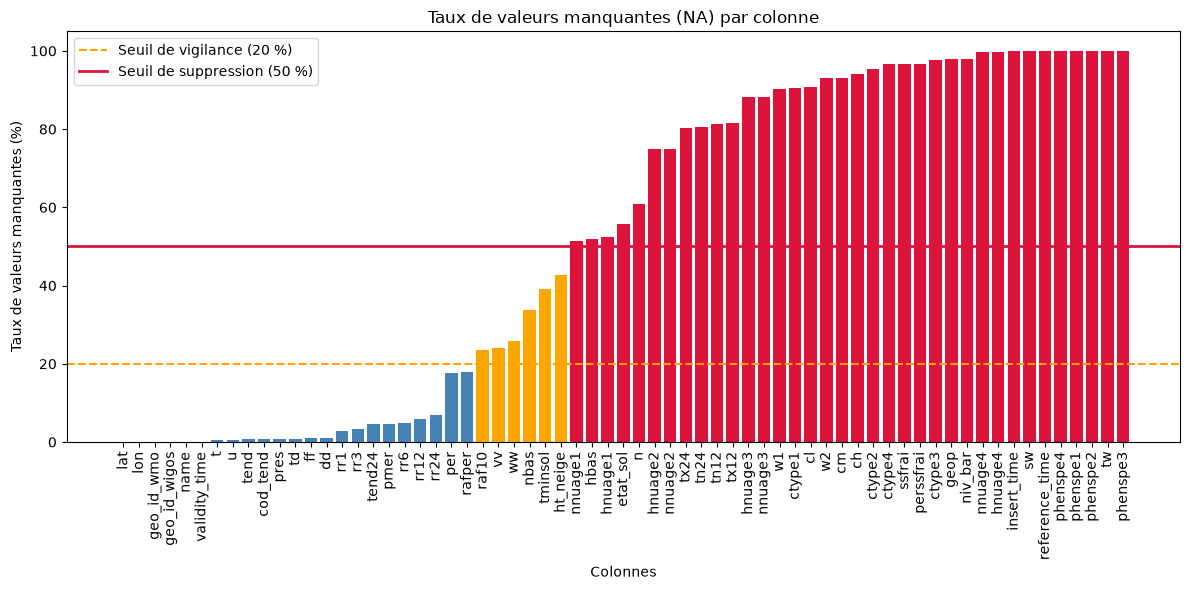

In [115]:
#graphique du taux de NA par colonne avec seuil de vigilance et seuil de suppression

# trie en fonction du taux de NA pour un affichage plus clair
resume_colonnes_tri = resume_colonnes.sort_values(by='Taux_NA (%)', ascending=True)

#Attribution des couleurs selon les seuils
couleurs = []
for val in resume_colonnes_tri['Taux_NA (%)'].values:
    if val >= 50:
        couleurs.append('crimson')       # Seuil suppression
    elif val >= 20:
        couleurs.append('orange')        # Seuil vigilance
    else:
        couleurs.append('steelblue')     # Données très complètes

#Figurre du graphique
plt.figure(figsize=(12, 6))
plt.bar(resume_colonnes_tri['Nom_Colonne'], resume_colonnes_tri['Taux_NA (%)'], color=couleurs)
plt.xticks(rotation=90)
plt.title("Taux de valeurs manquantes (NA) par colonne")
plt.xlabel("Colonnes")
plt.ylabel("Taux de valeurs manquantes (%)")
plt.axhline(y=20, color='orange', linestyle='--', linewidth=1.5, label='Seuil de vigilance (20 %)')
plt.axhline(y=50, color='crimson', linestyle='-', linewidth=2, label='Seuil de suppression (50 %)')
plt.legend()
plt.tight_layout()
plt.show()

In [116]:
#Taux de colonne qui ont > 50% de NA
colonnes_sup_50_na = resume_colonnes[resume_colonnes['Taux_NA (%)'] > 50]
print(f"Nombre de colonnes avec plus de 50% de valeurs manquantes : {colonnes_sup_50_na['Nom_Colonne'].count()}")

Nombre de colonnes avec plus de 50% de valeurs manquantes : 36


3. Aprés analyse des taux de NA et des données analyser par les capteurs, suppression des colonnes non gardé pour les futures analyses

In [117]:
#Supression des colonnes sélectionnées avec plus de 50% de NA et non pertinentes pour l'analyse
# Définition de la liste exacte des colonnes à conserver (Vert)
cols_a_garder = [
    'lat', 'lon',
    'name',
    'validity_time', 'pmer', 'tend', 
    'dd', 'ff', 't', 'td', 'u', 'vv', 'ww', 
    'pres', 
    'tend24', 
    'raf10', 'rafper', 'per', 
    'rr1', 'rr3', 'rr6', 'rr12', 'rr24'
]

# 2. Filtrage des colonnes du dataset concaténé
df_meteo_clean = df_meteo[cols_a_garder].copy()

df_meteo_clean.head(15)

,lat,lon,name,validity_time,pmer,tend,dd,ff,t,td,...,pres,tend24,raf10,rafper,per,rr1,rr3,rr6,rr12,rr24
0,50.136000,1.834000,ABBEVILLE,2021-01-01T00:00:00Z,100830.0,80.0,340.0,1.0,271.35,270.75,...,99920.0,570.0,2.0,3.3,-10.0,0.0,0.0,0.0,0.0,0.2
1,43.648833,7.209000,NICE,2021-01-01T00:00:00Z,100820.0,-90.0,330.0,3.0,280.15,274.85,...,100500.0,-60.0,5.0,7.5,-10.0,-0.1,-0.1,-0.1,-0.1,-0.1
2,47.444500,0.727333,TOURS,2021-01-01T00:00:00Z,100800.0,40.0,340.0,0.0,273.65,273.05,...,99410.0,360.0,0.9,1.7,-10.0,0.0,0.0,0.0,0.0,0.2
3,-20.892167,55.528667,GILLOT-AEROPORT,2021-01-01T00:00:00Z,101490.0,-80.0,160.0,5.0,296.25,293.55,...,101340.0,130.0,8.6,11.5,-10.0,0.4,1.8,2.6,2.6,3.6
4,47.059167,2.359833,BOURGES,2021-01-01T00:00:00Z,100860.0,70.0,0.0,0.0,272.85,272.25,...,98800.0,190.0,0.0,1.8,-10.0,0.0,0.0,0.0,0.0,7.1
5,43.437667,5.216000,MARIGNANE,2021-01-01T00:00:00Z,100550.0,-210.0,70.0,7.0,280.75,278.75,...,100160.0,-690.0,10.1,10.1,-10.0,0.4,0.6,0.6,0.6,1.2
6,-11.582667,47.289667,GLORIEUSES,2021-01-01T00:00:00Z,100970.0,70.0,80.0,1.0,299.05,296.55,...,100920.0,100.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
7,48.718000,2.397000,ORLY,2021-01-01T00:00:00Z,100810.0,80.0,270.0,1.0,272.75,272.15,...,99680.0,470.0,2.5,2.5,-10.0,0.0,0.0,0.0,0.0,2.0
8,48.324667,4.020000,TROYES-BARBEREY,2021-01-01T00:00:00Z,100750.0,80.0,270.0,2.0,274.15,272.85,...,99290.0,130.0,3.2,3.6,-10.0,0.2,0.2,0.2,0.8,1.6
9,4.822333,-52.365333,CAYENNE-MATOURY,2021-01-01T00:00:00Z,101250.0,160.0,150.0,0.0,298.65,298.35,...,101160.0,40.0,1.1,2.2,-10.0,0.0,0.0,0.0,0.0,1.0


In [118]:
df_meteo_clean.shape

(675000, 23)

In [119]:
# Export du fichier intermédiaire au format CSV (séparateur virgule ou point-virgule)
df_meteo_clean.to_csv('1.synop_2021_2024_intermediaire_suppCol.csv', index=False, sep=';')

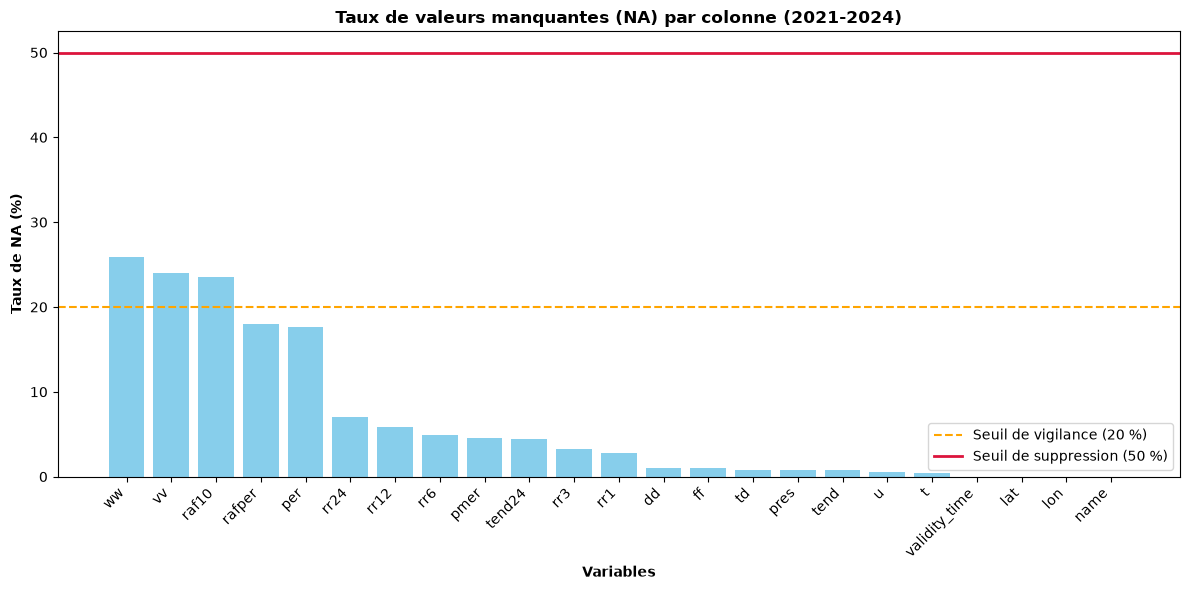

In [120]:
#Calcul du taux de NA par colonne en pourcentage
na_cols = df_meteo_clean.isna().mean() * 100
na_cols = na_cols.sort_values(ascending=False) # Tri décroissant pour plus de lisibilité en vertical

#Création du graphique en barres verticales
plt.figure(figsize=(12, 6))
plt.bar(na_cols.index, na_cols.values, color='skyblue')

# Ligne de seuil de vigilance à 50%
plt.axhline(y=20, color='orange', linestyle='--', linewidth=1.5, label='Seuil de vigilance (20 %)')
plt.axhline(y=50, color='crimson', linestyle='-', linewidth=2, label='Seuil de suppression (50 %)')

plt.title('Taux de valeurs manquantes (NA) par colonne (2021-2024)', fontsize=12, fontweight='bold')
plt.xlabel('Variables', fontweight='bold')
plt.ylabel('Taux de NA (%)', fontweight='bold')

# Rotation des étiquettes de l'axe X pour éviter qu'elles ne se superposent
plt.xticks(rotation=45, ha='right')

plt.legend()
plt.tight_layout()
plt.show()

In [121]:
#changement des noms decolonnes/variables pour plus de clarté et cohérence avec le rapport final
#dictionnaire de correspondance pour renommer les colonnes
dico_renommage = {
    'lat': 'latitude',
    'lon': 'longitude',
    'name': 'station_nom',
    'validity_time': 'date_mesure',
    'pmer': 'pression_mer',
    'tend': 'tendance_pression_3h',
    'dd': 'vent_direction',
    'ff': 'vent_vitesse',
    't': 'temperature_kelvin',
    'td': 'point_rosee',
    'u': 'humidite_relative',
    'vv': 'visibilite',
    'ww': 'temps_present',
    'pres': 'pression_station',
    'tend24': 'tendance_pression_24h',
    'raf10': 'rafale_10min',
    'rafper': 'rafale_periode',
    'per': 'periode_rafale',
    'rr1': 'precipitation_1h',
    'rr3': 'precipitation_3h',
    'rr6': 'precipitation_6h',
    'rr12': 'precipitation_12h',
    'rr24': 'precipitation_24h'
}

# Application du renommage sur le DataFrame
df_meteo_clean = df_meteo_clean.rename(columns=dico_renommage)

df_meteo_clean.head()

,latitude,longitude,station_nom,date_mesure,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,point_rosee,...,pression_station,tendance_pression_24h,rafale_10min,rafale_periode,periode_rafale,precipitation_1h,precipitation_3h,precipitation_6h,precipitation_12h,precipitation_24h
0,50.136000,1.834000,ABBEVILLE,2021-01-01T00:00:00Z,100830.0,80.0,340.0,1.0,271.35,270.75,...,99920.0,570.0,2.0,3.3,-10.0,0.0,0.0,0.0,0.0,0.2
1,43.648833,7.209000,NICE,2021-01-01T00:00:00Z,100820.0,-90.0,330.0,3.0,280.15,274.85,...,100500.0,-60.0,5.0,7.5,-10.0,-0.1,-0.1,-0.1,-0.1,-0.1
2,47.444500,0.727333,TOURS,2021-01-01T00:00:00Z,100800.0,40.0,340.0,0.0,273.65,273.05,...,99410.0,360.0,0.9,1.7,-10.0,0.0,0.0,0.0,0.0,0.2
3,-20.892167,55.528667,GILLOT-AEROPORT,2021-01-01T00:00:00Z,101490.0,-80.0,160.0,5.0,296.25,293.55,...,101340.0,130.0,8.6,11.5,-10.0,0.4,1.8,2.6,2.6,3.6
4,47.059167,2.359833,BOURGES,2021-01-01T00:00:00Z,100860.0,70.0,0.0,0.0,272.85,272.25,...,98800.0,190.0,0.0,1.8,-10.0,0.0,0.0,0.0,0.0,7.1


4. supprime les station météorologique en dehors de la France metropolitaine 

In [122]:
# Affichage de la liste unique des noms de stations présentes dans le dataset
print("Liste des stations (échantillon ou total) :")
display(df_meteo_clean['station_nom'].unique())

Liste des stations (échantillon ou total) :


<StringArray>
[              'ABBEVILLE',                    'NICE',
                   'TOURS',         'GILLOT-AEROPORT',
                 'BOURGES',               'MARIGNANE',
              'GLORIEUSES',                    'ORLY',
         'TROYES-BARBEREY',         'CAYENNE-MATOURY',
             'PLOUMANAC'H',      'LIMOGES-BELLEGARDE',
          'BREST-GUIPAVAS',               'KERGUELEN',
           'SAINT GEORGES',         'PTE DE LA HAGUE',
        'DUMONT D'URVILLE',           'LE PUY-LOUDES',
       'BORDEAUX-MERIGNAC',                  'CROZET',
                'TROMELIN',      'NOUVELLE AMSTERDAM',
       'RENNES-ST JACQUES',             'CLERMONT-FD',
           'SAINT LAURENT',          'LE RAIZET AERO',
              'MONTELIMAR',                 'GOURDON',
             'NANCY-OCHEY',        'TOULOUSE-BLAGNAC',
           'BALE-MULHOUSE',     'ST-BARTHELEMY METEO',
           'LAMENTIN-AERO',          'CAEN-CARPIQUET',
                  'EMBRUN',           'LILLE-LESQUI

In [123]:
#Filtrage géographique : Conservation de la France métropolitaine uniquement
# Bornes approximatives de la France métropolitaine : Lat [41.0, 51.1], Lon [-5.2, 9.6]

mask_metropole = (
    (df_meteo_clean['latitude'] >= 41.0) & (df_meteo_clean['latitude'] <= 51.1) &
    (df_meteo_clean['longitude'] >= -5.2) & (df_meteo_clean['longitude'] <= 9.6)
)

df_meteo_clean = df_meteo_clean[mask_metropole].copy()

print(df_meteo_clean.shape)

(463255, 23)


In [124]:
# Affichage de la liste unique des noms de stations présentes dans le dataset aprés filtrage géographique
print("Liste des stations france métropolitaine (échantillon ou total) :")
display(df_meteo_clean['station_nom'].unique())

Liste des stations france métropolitaine (échantillon ou total) :


<StringArray>
[              'ABBEVILLE',                    'NICE',
                   'TOURS',                 'BOURGES',
               'MARIGNANE',                    'ORLY',
         'TROYES-BARBEREY',             'PLOUMANAC'H',
      'LIMOGES-BELLEGARDE',          'BREST-GUIPAVAS',
         'PTE DE LA HAGUE',           'LE PUY-LOUDES',
       'BORDEAUX-MERIGNAC',       'RENNES-ST JACQUES',
             'CLERMONT-FD',              'MONTELIMAR',
                 'GOURDON',             'NANCY-OCHEY',
        'TOULOUSE-BLAGNAC',           'BALE-MULHOUSE',
          'CAEN-CARPIQUET',                  'EMBRUN',
           'LILLE-LESQUIN',                  'BASTIA',
         'LYON-ST EXUPERY',           'DIJON-LONGVIC',
               'PERPIGNAN',    'MONTPELLIER-AEROPORT',
          'MONT-DE-MARSAN',          'POITIERS-BIARD',
               'ST GIRONS',               'CHASSIRON',
                 'AJACCIO',     'STRASBOURG-ENTZHEIM',
       'NANTES-BOUGUENAIS', 'TARBES-LOURDES-PYRENEE

5. Remplacement des NA

In [125]:
# Tri indispensable avant toute interpolation temporelle
df_meteo_clean = df_meteo_clean.sort_values(by=['station_nom', 'date_mesure']).reset_index(drop=True)

df_meteo_clean.head(20)

,latitude,longitude,station_nom,date_mesure,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,point_rosee,...,pression_station,tendance_pression_24h,rafale_10min,rafale_periode,periode_rafale,precipitation_1h,precipitation_3h,precipitation_6h,precipitation_12h,precipitation_24h
0,50.136,1.834,ABBEVILLE,2021-01-01T00:00:00Z,100830.0,80.0,340.0,1.0,271.35,270.75,...,99920.0,570.0,2.0,3.3,-10.0,0.0,0.0,0.0,0.0,0.2
1,50.136,1.834,ABBEVILLE,2021-01-01T03:00:00Z,100910.0,90.0,10.0,1.0,272.15,270.85,...,100010.0,740.0,2.3,3.5,-10.0,0.0,0.0,0.0,0.0,-0.1
2,50.136,1.834,ABBEVILLE,2021-01-01T06:00:00Z,100960.0,50.0,240.0,1.0,272.65,271.55,...,100060.0,780.0,2.3,2.4,-10.0,0.0,0.0,0.0,0.0,0.0
3,50.136,1.834,ABBEVILLE,2021-01-01T09:00:00Z,101100.0,140.0,200.0,0.0,273.35,272.95,...,100200.0,780.0,1.5,1.7,-10.0,0.0,0.0,0.0,0.0,0.0
4,50.136,1.834,ABBEVILLE,2021-01-01T12:00:00Z,101140.0,50.0,150.0,1.0,276.55,271.95,...,100250.0,760.0,1.9,1.9,-10.0,0.2,0.2,0.2,0.2,0.2
5,50.136,1.834,ABBEVILLE,2021-01-01T15:00:00Z,101160.0,20.0,260.0,0.0,276.45,272.05,...,100270.0,690.0,1.1,1.5,-10.0,0.0,0.0,0.2,0.2,0.2
6,50.136,1.834,ABBEVILLE,2021-01-01T18:00:00Z,101250.0,80.0,170.0,0.0,274.15,272.25,...,100350.0,650.0,1.3,1.4,-10.0,0.0,0.0,0.0,0.2,0.2
7,50.136,1.834,ABBEVILLE,2021-01-01T21:00:00Z,101370.0,110.0,150.0,1.0,272.75,271.95,...,100460.0,620.0,2.2,2.3,-10.0,0.0,0.0,0.0,0.2,0.2
8,50.136,1.834,ABBEVILLE,2021-01-02T00:00:00Z,101420.0,50.0,170.0,1.0,271.65,271.35,...,100510.0,590.0,2.2,2.5,-10.0,0.0,0.0,0.0,0.0,0.2
9,50.136,1.834,ABBEVILLE,2021-01-02T03:00:00Z,101460.0,40.0,150.0,1.0,271.85,271.75,...,100550.0,540.0,2.1,2.4,-10.0,0.0,0.0,0.0,0.0,0.2


In [126]:
# Conversion explicite de la colonne date_mesure au format datetime
df_meteo_clean['date_mesure'] = pd.to_datetime(df_meteo_clean['date_mesure'])

df_meteo_clean.info()

df_meteo_clean.head(20)

<class 'pandas.DataFrame'>
RangeIndex: 463255 entries, 0 to 463254
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype              
---  ------                 --------------   -----              
 0   latitude               463255 non-null  float64            
 1   longitude              463255 non-null  float64            
 2   station_nom            463255 non-null  str                
 3   date_mesure            463255 non-null  datetime64[us, UTC]
 4   pression_mer           439582 non-null  float64            
 5   tendance_pression_3h   463032 non-null  float64            
 6   vent_direction         462392 non-null  float64            
 7   vent_vitesse           462412 non-null  float64            
 8   temperature_kelvin     462821 non-null  float64            
 9   point_rosee            462679 non-null  float64            
 10  humidite_relative      462693 non-null  float64            
 11  visibilite             438343 non-null  float64   

,latitude,longitude,station_nom,date_mesure,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,point_rosee,...,pression_station,tendance_pression_24h,rafale_10min,rafale_periode,periode_rafale,precipitation_1h,precipitation_3h,precipitation_6h,precipitation_12h,precipitation_24h
0,50.136,1.834,ABBEVILLE,2021-01-01 00:00:00+00:00,100830.0,80.0,340.0,1.0,271.35,270.75,...,99920.0,570.0,2.0,3.3,-10.0,0.0,0.0,0.0,0.0,0.2
1,50.136,1.834,ABBEVILLE,2021-01-01 03:00:00+00:00,100910.0,90.0,10.0,1.0,272.15,270.85,...,100010.0,740.0,2.3,3.5,-10.0,0.0,0.0,0.0,0.0,-0.1
2,50.136,1.834,ABBEVILLE,2021-01-01 06:00:00+00:00,100960.0,50.0,240.0,1.0,272.65,271.55,...,100060.0,780.0,2.3,2.4,-10.0,0.0,0.0,0.0,0.0,0.0
3,50.136,1.834,ABBEVILLE,2021-01-01 09:00:00+00:00,101100.0,140.0,200.0,0.0,273.35,272.95,...,100200.0,780.0,1.5,1.7,-10.0,0.0,0.0,0.0,0.0,0.0
4,50.136,1.834,ABBEVILLE,2021-01-01 12:00:00+00:00,101140.0,50.0,150.0,1.0,276.55,271.95,...,100250.0,760.0,1.9,1.9,-10.0,0.2,0.2,0.2,0.2,0.2
5,50.136,1.834,ABBEVILLE,2021-01-01 15:00:00+00:00,101160.0,20.0,260.0,0.0,276.45,272.05,...,100270.0,690.0,1.1,1.5,-10.0,0.0,0.0,0.2,0.2,0.2
6,50.136,1.834,ABBEVILLE,2021-01-01 18:00:00+00:00,101250.0,80.0,170.0,0.0,274.15,272.25,...,100350.0,650.0,1.3,1.4,-10.0,0.0,0.0,0.0,0.2,0.2
7,50.136,1.834,ABBEVILLE,2021-01-01 21:00:00+00:00,101370.0,110.0,150.0,1.0,272.75,271.95,...,100460.0,620.0,2.2,2.3,-10.0,0.0,0.0,0.0,0.2,0.2
8,50.136,1.834,ABBEVILLE,2021-01-02 00:00:00+00:00,101420.0,50.0,170.0,1.0,271.65,271.35,...,100510.0,590.0,2.2,2.5,-10.0,0.0,0.0,0.0,0.0,0.2
9,50.136,1.834,ABBEVILLE,2021-01-02 03:00:00+00:00,101460.0,40.0,150.0,1.0,271.85,271.75,...,100550.0,540.0,2.1,2.4,-10.0,0.0,0.0,0.0,0.0,0.2


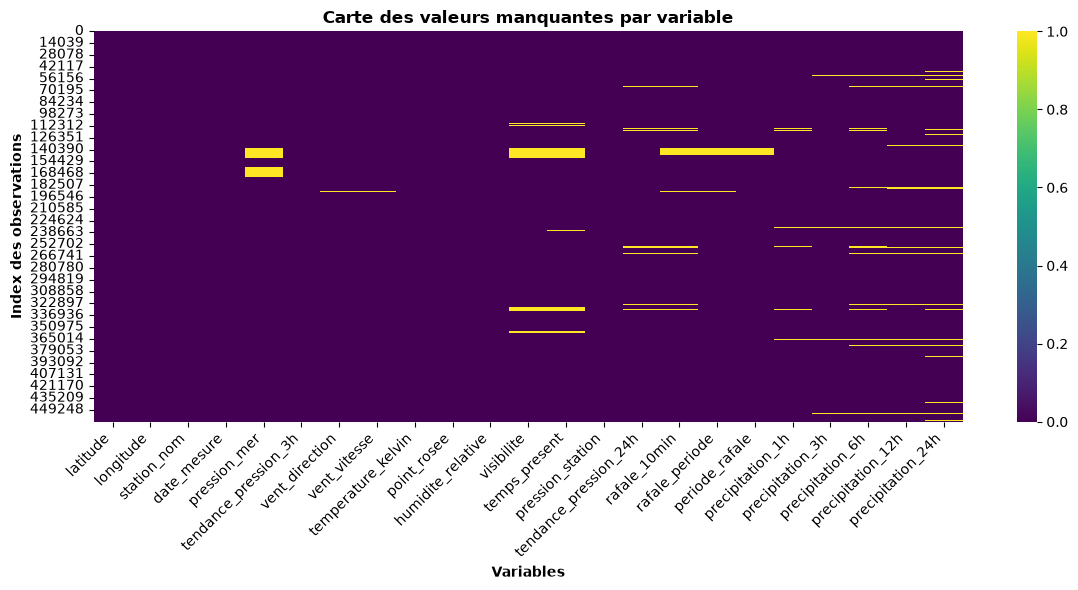

In [127]:
# Heatmap simple des valeurs manquantes (les zones claires/jaunes représentent les NA)
plt.figure(figsize=(12, 6))
sns.heatmap(df_meteo_clean.isna(), cbar=True, cmap='viridis')

plt.title("Carte des valeurs manquantes par variable", fontsize=12, fontweight='bold')
plt.xlabel("Variables", fontweight='bold')
plt.ylabel("Index des observations", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#on peut faire une interpolation linéaire station par station pour les variables continues.

In [128]:
df_meteo_clean.head(10)

,latitude,longitude,station_nom,date_mesure,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,point_rosee,...,pression_station,tendance_pression_24h,rafale_10min,rafale_periode,periode_rafale,precipitation_1h,precipitation_3h,precipitation_6h,precipitation_12h,precipitation_24h
0,50.136,1.834,ABBEVILLE,2021-01-01 00:00:00+00:00,100830.0,80.0,340.0,1.0,271.35,270.75,...,99920.0,570.0,2.0,3.3,-10.0,0.0,0.0,0.0,0.0,0.2
1,50.136,1.834,ABBEVILLE,2021-01-01 03:00:00+00:00,100910.0,90.0,10.0,1.0,272.15,270.85,...,100010.0,740.0,2.3,3.5,-10.0,0.0,0.0,0.0,0.0,-0.1
2,50.136,1.834,ABBEVILLE,2021-01-01 06:00:00+00:00,100960.0,50.0,240.0,1.0,272.65,271.55,...,100060.0,780.0,2.3,2.4,-10.0,0.0,0.0,0.0,0.0,0.0
3,50.136,1.834,ABBEVILLE,2021-01-01 09:00:00+00:00,101100.0,140.0,200.0,0.0,273.35,272.95,...,100200.0,780.0,1.5,1.7,-10.0,0.0,0.0,0.0,0.0,0.0
4,50.136,1.834,ABBEVILLE,2021-01-01 12:00:00+00:00,101140.0,50.0,150.0,1.0,276.55,271.95,...,100250.0,760.0,1.9,1.9,-10.0,0.2,0.2,0.2,0.2,0.2
5,50.136,1.834,ABBEVILLE,2021-01-01 15:00:00+00:00,101160.0,20.0,260.0,0.0,276.45,272.05,...,100270.0,690.0,1.1,1.5,-10.0,0.0,0.0,0.2,0.2,0.2
6,50.136,1.834,ABBEVILLE,2021-01-01 18:00:00+00:00,101250.0,80.0,170.0,0.0,274.15,272.25,...,100350.0,650.0,1.3,1.4,-10.0,0.0,0.0,0.0,0.2,0.2
7,50.136,1.834,ABBEVILLE,2021-01-01 21:00:00+00:00,101370.0,110.0,150.0,1.0,272.75,271.95,...,100460.0,620.0,2.2,2.3,-10.0,0.0,0.0,0.0,0.2,0.2
8,50.136,1.834,ABBEVILLE,2021-01-02 00:00:00+00:00,101420.0,50.0,170.0,1.0,271.65,271.35,...,100510.0,590.0,2.2,2.5,-10.0,0.0,0.0,0.0,0.0,0.2
9,50.136,1.834,ABBEVILLE,2021-01-02 03:00:00+00:00,101460.0,40.0,150.0,1.0,271.85,271.75,...,100550.0,540.0,2.1,2.4,-10.0,0.0,0.0,0.0,0.0,0.2


In [129]:
# Interpolation linéaire station par station pour les variables continues

cols_continues = [
    'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse',
    'temperature_kelvin', 'point_rosee', 'humidite_relative', 'visibilite',
    'pression_station', 'tendance_pression_24h', 'rafale_10min', 'rafale_periode', 'periode_rafale'
]

for col in cols_continues:
    if col in df_meteo_clean.columns:
        df_meteo_clean[col] = df_meteo_clean.groupby('station_nom')[col].transform(
            lambda x: x.interpolate(method='linear', limit_direction='both')
        )

In [130]:
#Gestion des précipitations : remplacement des NA par 0 (absence de pluie)
cols_precip = ['precipitation_1h', 'precipitation_3h', 'precipitation_6h', 'precipitation_12h', 'precipitation_24h']
for col in cols_precip:
    if col in df_meteo_clean.columns:
        df_meteo_clean[col] = df_meteo_clean[col].fillna(0)

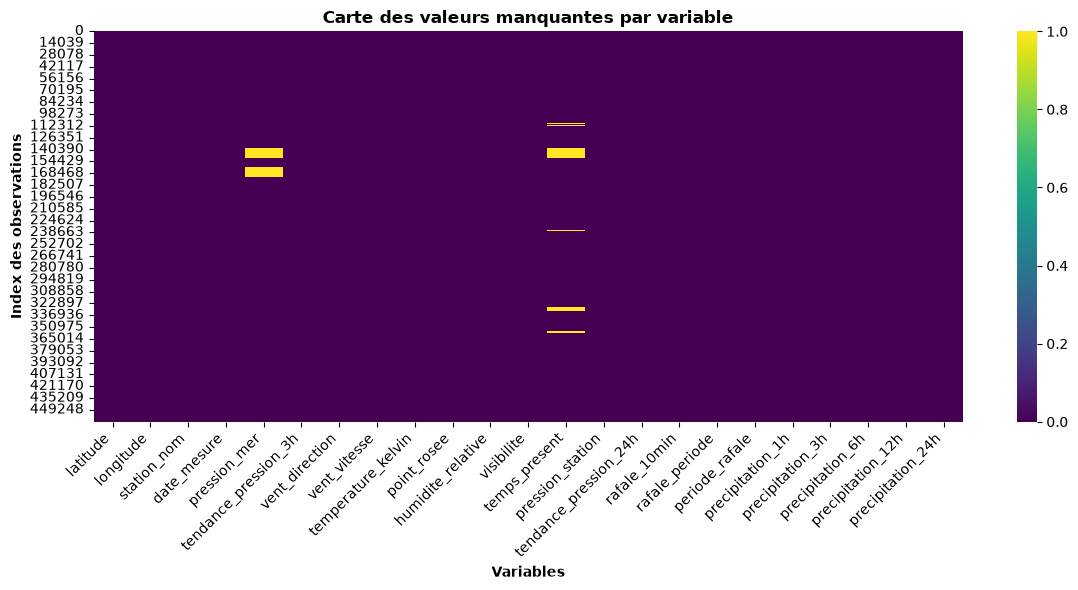

In [131]:
# Heatmap simple des valeurs manquantes (les zones claires/jaunes représentent les NA)
plt.figure(figsize=(12, 6))
sns.heatmap(df_meteo_clean.isna(), cbar=True, cmap='viridis')

plt.title("Carte des valeurs manquantes par variable", fontsize=12, fontweight='bold')
plt.xlabel("Variables", fontweight='bold')
plt.ylabel("Index des observations", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

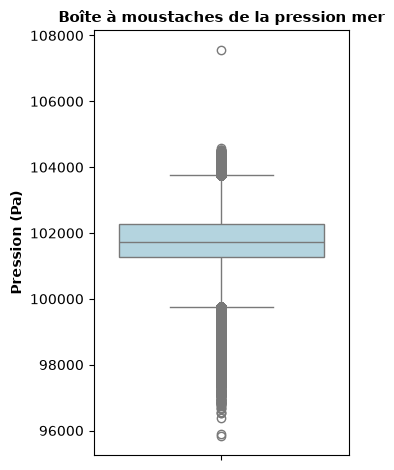

In [132]:
#reste des na sur pression mer
#regarder la répartition
plt.subplot(1, 2, 2)
sns.boxplot(y=df_meteo_clean['pression_mer'], color='lightblue')
plt.title("Boîte à moustaches de la pression mer", fontsize=11, fontweight='bold')
plt.ylabel("Pression (Pa)", fontweight='bold')

plt.tight_layout()
plt.show()

#la varation de la pression mer est faible, on peut donc remplacer les NA par la médian  de la station

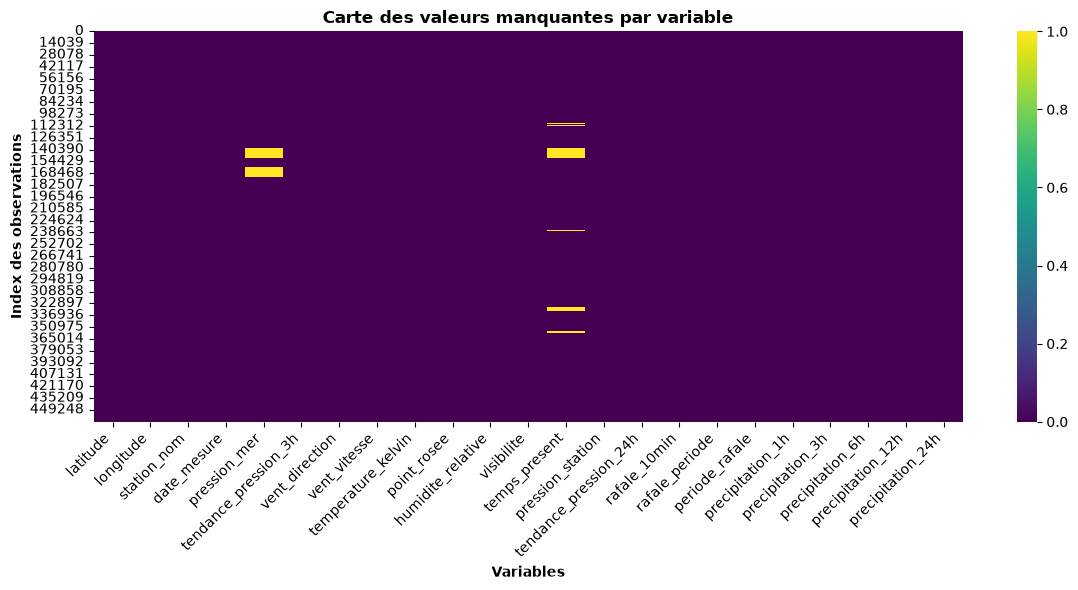

In [133]:
# Remplacement des NA restants sur pression_mer par la médiane de chaque station
df_meteo_clean['pression_mer'] = df_meteo_clean.groupby('station_nom')['pression_mer'].transform(
    lambda x: x.fillna(x.median())
)

# Heatmap simple des valeurs manquantes (les zones claires/jaunes représentent les NA)
plt.figure(figsize=(12, 6))
sns.heatmap(df_meteo_clean.isna(), cbar=True, cmap='viridis')

plt.title("Carte des valeurs manquantes par variable", fontsize=12, fontweight='bold')
plt.xlabel("Variables", fontweight='bold')
plt.ylabel("Index des observations", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

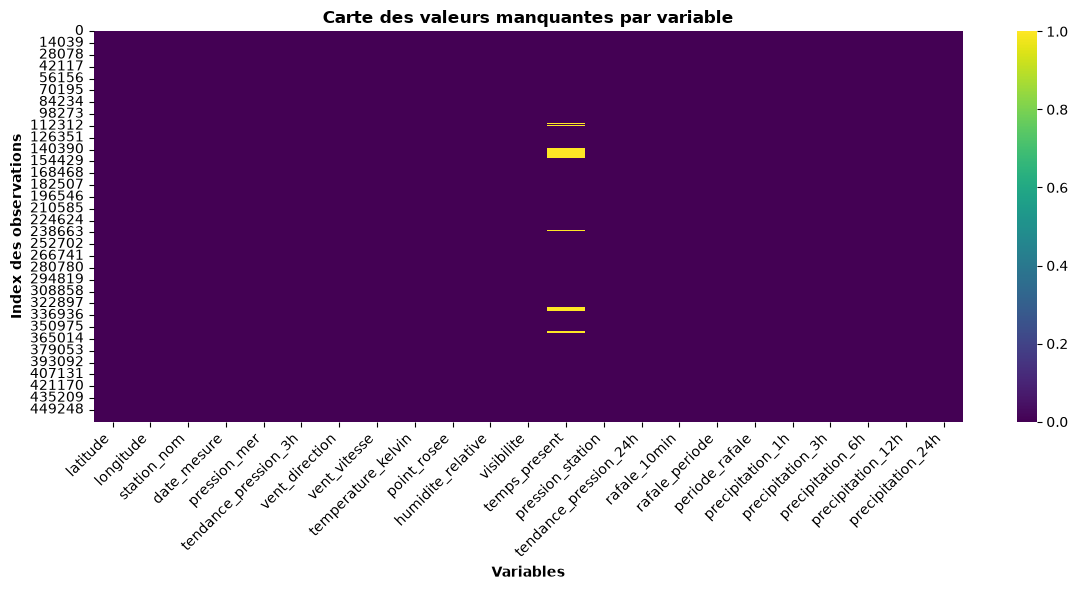

In [134]:
# la station n'a pas de données sur la pression mer, on remplace par la médiane globale
df_meteo_clean['pression_mer'] = df_meteo_clean['pression_mer'].fillna(df_meteo_clean['pression_mer'].median())


# Heatmap simple des valeurs manquantes (les zones claires/jaunes représentent les NA)
plt.figure(figsize=(12, 6))
sns.heatmap(df_meteo_clean.isna(), cbar=True, cmap='viridis')

plt.title("Carte des valeurs manquantes par variable", fontsize=12, fontweight='bold')
plt.xlabel("Variables", fontweight='bold')
plt.ylabel("Index des observations", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [135]:
df_meteo_clean['temps_present'].unique()

array([ 0., 10., 45., 60., 61., 49., 58., 63., 53., 69., 73., 68., 51.,
       50., 71., 70., 52., 65., 62., 41., 44., nan, 66., 48., 64., 75.,
       55., 81., 59., 54.,  1.,  3.,  2., 22., 21., 14., 15., 26., 25.,
       80., 20., 78., 86., 17., 29., 95., 47., 43., 28., 11., 42., 46.,
       40., 85., 91., 87., 56., 16., 18., 13., 27., 31., 97., 84., 82.,
       24., 23., 12., 72., 92., 79.,  4., 77., 83., 89., 90.,  5.])

In [136]:
#Encodage de la variables catégorielles temps_present pour retirer les NA et les remplacer par une catégorie "inconnue"
def categoriser_temps_present_wmo(code):
    if pd.isna(code):
        return 'temps_inconnu'  # Remplacement des NaN ici
    code = int(code)
    
    # 0 à 9 : Pas de précipitation, pas de brouillard, ni orage dans l'heure (développement nuageux, visibilité altérée)
    if 0 <= code <= 9:
        return 'sans_precipitation_visibilite_ou_nuages'
    # 10 à 19 : Brume, fumée, virga, éclairs, ou événements particuliers sans précipitation au sol à la station
    elif 10 <= code <= 19:
        return 'brume_fumee_ou_phenomenes_particuliers'
    # 20 à 29 : Phénomènes récents au cours de la dernière heure (précipitations, orage, brouillard)
    elif 20 <= code <= 29:
        return 'phenomenes_recents_derniere_heure'
    # 30 à 39 : Tempêtes de poussière, chasse-neige
    elif 30 <= code <= 39:
        return 'tempete_poussiere_chasse_neige'
    # 40 à 49 : Brouillard ou brume givrante
    elif 40 <= code <= 49:
        return 'brouillard'
    # 50 à 69 : Bruine et pluie
    elif 50 <= code <= 69:
        return 'pluie_ou_bruine'
    # 70 à 79 : Neige et précipitations solides
    elif 70 <= code <= 79:
        return 'neige_precipitation_solide'
    # 80 à 99 : Averses, orages et grêle
    elif 80 <= code <= 99:
        return 'averses_ou_orages'
    else:
        return 'autre'

# Application sur le DataFrame
df_meteo_clean['tp'] = df_meteo_clean['temps_present'].apply(categoriser_temps_present_wmo)

# Vérification des catégories uniques obtenues
print(df_meteo_clean['tp'].unique())

<StringArray>
['sans_precipitation_visibilite_ou_nuages',
  'brume_fumee_ou_phenomenes_particuliers',
                              'brouillard',
                         'pluie_ou_bruine',
              'neige_precipitation_solide',
                           'temps_inconnu',
                       'averses_ou_orages',
       'phenomenes_recents_derniere_heure',
          'tempete_poussiere_chasse_neige']
Length: 9, dtype: str


In [137]:
df_meteo_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 463255 entries, 0 to 463254
Data columns (total 24 columns):
 #   Column                 Non-Null Count   Dtype              
---  ------                 --------------   -----              
 0   latitude               463255 non-null  float64            
 1   longitude              463255 non-null  float64            
 2   station_nom            463255 non-null  str                
 3   date_mesure            463255 non-null  datetime64[us, UTC]
 4   pression_mer           463255 non-null  float64            
 5   tendance_pression_3h   463255 non-null  float64            
 6   vent_direction         463255 non-null  float64            
 7   vent_vitesse           463255 non-null  float64            
 8   temperature_kelvin     463255 non-null  float64            
 9   point_rosee            463255 non-null  float64            
 10  humidite_relative      463255 non-null  float64            
 11  visibilite             463255 non-null  float64   

In [138]:
from sklearn.preprocessing import OneHotEncoder

# Initialisation du OneHotEncoder
# sparse_output=False permet de retourner directement un tableau numpy (compatible DataFrame)
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# Ajustement et transformation de la colonne
encoded_array = encoder.fit_transform(df_meteo_clean[['tp']])

# Récupération des noms de colonnes propres générés par l'encodeur
encoded_feature_names = encoder.get_feature_names_out(['tp'])

# Création d'un DataFrame temporaire avec ces colonnes
df_encoded = pd.DataFrame(encoded_array, columns=encoded_feature_names, index=df_meteo_clean.index)

# Concaténation avec le DataFrame principal et suppression de l'ancienne colonne textuelle
df_meteo_clean = pd.concat([df_meteo_clean.drop(columns=['tp']), df_encoded], axis=1)

df_meteo_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 463255 entries, 0 to 463254
Data columns (total 32 columns):
 #   Column                                      Non-Null Count   Dtype              
---  ------                                      --------------   -----              
 0   latitude                                    463255 non-null  float64            
 1   longitude                                   463255 non-null  float64            
 2   station_nom                                 463255 non-null  str                
 3   date_mesure                                 463255 non-null  datetime64[us, UTC]
 4   pression_mer                                463255 non-null  float64            
 5   tendance_pression_3h                        463255 non-null  float64            
 6   vent_direction                              463255 non-null  float64            
 7   vent_vitesse                                463255 non-null  float64            
 8   temperature_kelvin                 

In [139]:
# Suppression de la colonne brute d'origine ('temps_present') 
df_meteo_clean = df_meteo_clean.drop(['temps_present'], axis=1, errors='ignore')

df_meteo_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 463255 entries, 0 to 463254
Data columns (total 31 columns):
 #   Column                                      Non-Null Count   Dtype              
---  ------                                      --------------   -----              
 0   latitude                                    463255 non-null  float64            
 1   longitude                                   463255 non-null  float64            
 2   station_nom                                 463255 non-null  str                
 3   date_mesure                                 463255 non-null  datetime64[us, UTC]
 4   pression_mer                                463255 non-null  float64            
 5   tendance_pression_3h                        463255 non-null  float64            
 6   vent_direction                              463255 non-null  float64            
 7   vent_vitesse                                463255 non-null  float64            
 8   temperature_kelvin                 

In [140]:
df_meteo_clean.to_csv('2.df_meteo_clean_sans_na.csv', index=False)

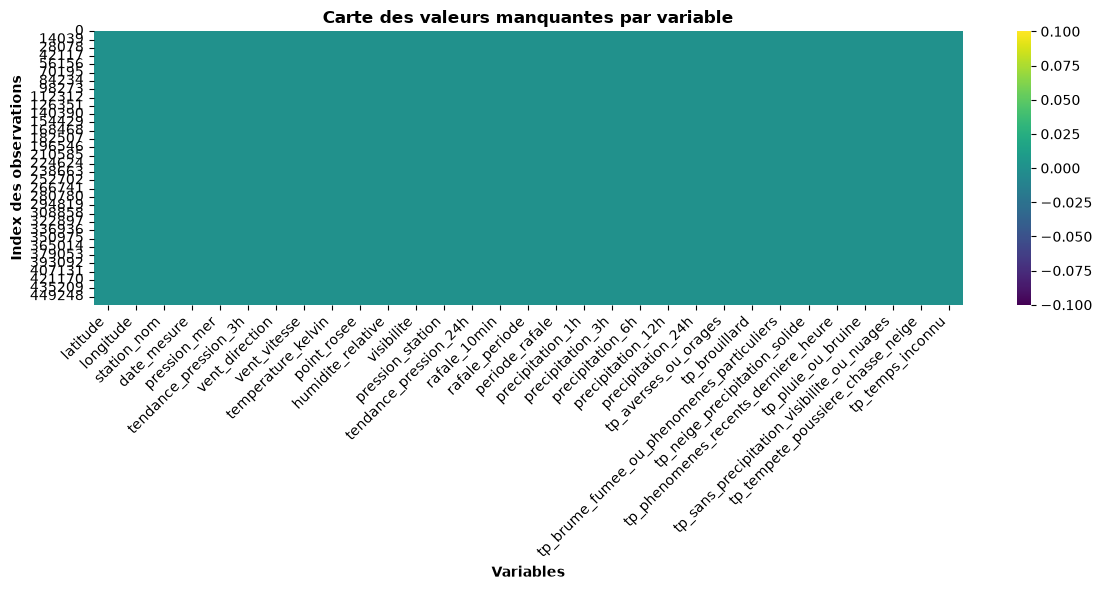

In [141]:
# Heatmap simple des valeurs manquantes (les zones claires/jaunes représentent les NA)
plt.figure(figsize=(12, 6))
sns.heatmap(df_meteo_clean.isna(), cbar=True, cmap='viridis')

plt.title("Carte des valeurs manquantes par variable", fontsize=12, fontweight='bold')
plt.xlabel("Variables", fontweight='bold')
plt.ylabel("Index des observations", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

6. Ajout des code départements

In [142]:
# Associé le département à chaque station météo en utilisant API officielle du gouvernement français (geo.api.gouv.fr)
import requests

# Récupération des départements uniquement sur les stations uniques
stations_unique = df_meteo_clean[['station_nom', 'latitude', 'longitude']].drop_duplicates().copy()

def get_departement(lat, lon):
    try:
        url = f"https://geo.api.gouv.fr/communes?lat={lat}&lon={lon}&fields=codeDepartement&format=json"
        response = requests.get(url, timeout=5)
        data = response.json()
        if data:
            return data[0]['codeDepartement']
    except Exception as e:
        pass
    return None

stations_unique['code_dept'] = stations_unique.apply(
    lambda row: get_departement(row['latitude'], row['longitude']), axis=1
)


stations_unique.head(10)

,station_nom,latitude,longitude,code_dept
0,ABBEVILLE,50.136000,1.834000,80
11570,AJACCIO,41.918000,8.792667,2A
23233,ALENCON,48.445500,0.110167,61
34804,BALE-MULHOUSE,47.614333,7.510000,68
46471,BASTIA,42.540667,9.485167,2B
58134,BORDEAUX-MERIGNAC,44.830667,-0.691333,33
69801,BOURGES,47.059167,2.359833,18
81468,BREST-GUIPAVAS,48.453833,-4.391167,29
93115,CAEN-CARPIQUET,49.180000,-0.456167,14
104732,CHASSIRON,46.046833,-1.411667,17


In [143]:
# Fusion pour ajouter la colonne 'code_dept'
df_meteo_clean = df_meteo_clean.merge(
    stations_unique[['station_nom', 'code_dept']], 
    on='station_nom', 
    how='left'
)

df_meteo_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 463255 entries, 0 to 463254
Data columns (total 32 columns):
 #   Column                                      Non-Null Count   Dtype              
---  ------                                      --------------   -----              
 0   latitude                                    463255 non-null  float64            
 1   longitude                                   463255 non-null  float64            
 2   station_nom                                 463255 non-null  str                
 3   date_mesure                                 463255 non-null  datetime64[us, UTC]
 4   pression_mer                                463255 non-null  float64            
 5   tendance_pression_3h                        463255 non-null  float64            
 6   vent_direction                              463255 non-null  float64            
 7   vent_vitesse                                463255 non-null  float64            
 8   temperature_kelvin                 

In [144]:
df_meteo_clean.head(10)

,latitude,longitude,station_nom,date_mesure,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,point_rosee,...,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu,code_dept
0,50.136,1.834,ABBEVILLE,2021-01-01 00:00:00+00:00,100830.0,80.0,340.0,1.0,271.35,270.75,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,80
1,50.136,1.834,ABBEVILLE,2021-01-01 03:00:00+00:00,100910.0,90.0,10.0,1.0,272.15,270.85,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,80
2,50.136,1.834,ABBEVILLE,2021-01-01 06:00:00+00:00,100960.0,50.0,240.0,1.0,272.65,271.55,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,80
3,50.136,1.834,ABBEVILLE,2021-01-01 09:00:00+00:00,101100.0,140.0,200.0,0.0,273.35,272.95,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,80
4,50.136,1.834,ABBEVILLE,2021-01-01 12:00:00+00:00,101140.0,50.0,150.0,1.0,276.55,271.95,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,80
5,50.136,1.834,ABBEVILLE,2021-01-01 15:00:00+00:00,101160.0,20.0,260.0,0.0,276.45,272.05,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,80
6,50.136,1.834,ABBEVILLE,2021-01-01 18:00:00+00:00,101250.0,80.0,170.0,0.0,274.15,272.25,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,80
7,50.136,1.834,ABBEVILLE,2021-01-01 21:00:00+00:00,101370.0,110.0,150.0,1.0,272.75,271.95,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,80
8,50.136,1.834,ABBEVILLE,2021-01-02 00:00:00+00:00,101420.0,50.0,170.0,1.0,271.65,271.35,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,80
9,50.136,1.834,ABBEVILLE,2021-01-02 03:00:00+00:00,101460.0,40.0,150.0,1.0,271.85,271.75,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,80


In [145]:
df_meteo_clean['code_dept'].unique()


<StringArray>
['80', '2A', '61', '68', '2B', '33', '18', '29', '14', '17', '63', '21', '05',
 '46', '43', '59', '87', '69', '13', '12', '40', '26', '34', '54', '44', '06',
 '91', '66', '22', '86', '50', '51', '35', '76', '09', '67', '65', '31', '37',
 '10']
Length: 40, dtype: str

In [146]:
# Réorganisation des colonnes pour placer 'code_dept' en première position
cols = list(df_meteo_clean.columns)

if 'code_dept' in cols:
    cols.remove('code_dept')

# Insertion en 0 (première position)
cols.insert(0, 'code_dept')

# Réapplication de l'ordre au DataFrame
df_meteo_clean = df_meteo_clean[cols]

display(df_meteo_clean.head(10))
display(df_meteo_clean.info())
display(df_meteo_clean['code_dept'].unique())

,code_dept,latitude,longitude,station_nom,date_mesure,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,...,precipitation_24h,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu
0,80,50.136,1.834,ABBEVILLE,2021-01-01 00:00:00+00:00,100830.0,80.0,340.0,1.0,271.35,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,80,50.136,1.834,ABBEVILLE,2021-01-01 03:00:00+00:00,100910.0,90.0,10.0,1.0,272.15,...,-0.1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,80,50.136,1.834,ABBEVILLE,2021-01-01 06:00:00+00:00,100960.0,50.0,240.0,1.0,272.65,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,80,50.136,1.834,ABBEVILLE,2021-01-01 09:00:00+00:00,101100.0,140.0,200.0,0.0,273.35,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,80,50.136,1.834,ABBEVILLE,2021-01-01 12:00:00+00:00,101140.0,50.0,150.0,1.0,276.55,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
5,80,50.136,1.834,ABBEVILLE,2021-01-01 15:00:00+00:00,101160.0,20.0,260.0,0.0,276.45,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6,80,50.136,1.834,ABBEVILLE,2021-01-01 18:00:00+00:00,101250.0,80.0,170.0,0.0,274.15,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7,80,50.136,1.834,ABBEVILLE,2021-01-01 21:00:00+00:00,101370.0,110.0,150.0,1.0,272.75,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
8,80,50.136,1.834,ABBEVILLE,2021-01-02 00:00:00+00:00,101420.0,50.0,170.0,1.0,271.65,...,0.2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9,80,50.136,1.834,ABBEVILLE,2021-01-02 03:00:00+00:00,101460.0,40.0,150.0,1.0,271.85,...,0.2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


<class 'pandas.DataFrame'>
RangeIndex: 463255 entries, 0 to 463254
Data columns (total 32 columns):
 #   Column                                      Non-Null Count   Dtype              
---  ------                                      --------------   -----              
 0   code_dept                                   463255 non-null  str                
 1   latitude                                    463255 non-null  float64            
 2   longitude                                   463255 non-null  float64            
 3   station_nom                                 463255 non-null  str                
 4   date_mesure                                 463255 non-null  datetime64[us, UTC]
 5   pression_mer                                463255 non-null  float64            
 6   tendance_pression_3h                        463255 non-null  float64            
 7   vent_direction                              463255 non-null  float64            
 8   vent_vitesse                       

None

<StringArray>
['80', '2A', '61', '68', '2B', '33', '18', '29', '14', '17', '63', '21', '05',
 '46', '43', '59', '87', '69', '13', '12', '40', '26', '34', '54', '44', '06',
 '91', '66', '22', '86', '50', '51', '35', '76', '09', '67', '65', '31', '37',
 '10']
Length: 40, dtype: str

In [147]:
# Suppression sécurisée (on ne supprime que celles qui existent dans le DataFrame)
df_meteo_clean = df_meteo_clean.drop(columns=['station_nom'], errors='ignore')

display(df_meteo_clean.head(10))
display(df_meteo_clean.info())
display(df_meteo_clean['code_dept'].unique())

,code_dept,latitude,longitude,date_mesure,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,point_rosee,...,precipitation_24h,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu
0,80,50.136,1.834,2021-01-01 00:00:00+00:00,100830.0,80.0,340.0,1.0,271.35,270.75,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,80,50.136,1.834,2021-01-01 03:00:00+00:00,100910.0,90.0,10.0,1.0,272.15,270.85,...,-0.1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,80,50.136,1.834,2021-01-01 06:00:00+00:00,100960.0,50.0,240.0,1.0,272.65,271.55,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,80,50.136,1.834,2021-01-01 09:00:00+00:00,101100.0,140.0,200.0,0.0,273.35,272.95,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,80,50.136,1.834,2021-01-01 12:00:00+00:00,101140.0,50.0,150.0,1.0,276.55,271.95,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
5,80,50.136,1.834,2021-01-01 15:00:00+00:00,101160.0,20.0,260.0,0.0,276.45,272.05,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6,80,50.136,1.834,2021-01-01 18:00:00+00:00,101250.0,80.0,170.0,0.0,274.15,272.25,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7,80,50.136,1.834,2021-01-01 21:00:00+00:00,101370.0,110.0,150.0,1.0,272.75,271.95,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
8,80,50.136,1.834,2021-01-02 00:00:00+00:00,101420.0,50.0,170.0,1.0,271.65,271.35,...,0.2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9,80,50.136,1.834,2021-01-02 03:00:00+00:00,101460.0,40.0,150.0,1.0,271.85,271.75,...,0.2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


<class 'pandas.DataFrame'>
RangeIndex: 463255 entries, 0 to 463254
Data columns (total 31 columns):
 #   Column                                      Non-Null Count   Dtype              
---  ------                                      --------------   -----              
 0   code_dept                                   463255 non-null  str                
 1   latitude                                    463255 non-null  float64            
 2   longitude                                   463255 non-null  float64            
 3   date_mesure                                 463255 non-null  datetime64[us, UTC]
 4   pression_mer                                463255 non-null  float64            
 5   tendance_pression_3h                        463255 non-null  float64            
 6   vent_direction                              463255 non-null  float64            
 7   vent_vitesse                                463255 non-null  float64            
 8   temperature_kelvin                 

None

<StringArray>
['80', '2A', '61', '68', '2B', '33', '18', '29', '14', '17', '63', '21', '05',
 '46', '43', '59', '87', '69', '13', '12', '40', '26', '34', '54', '44', '06',
 '91', '66', '22', '86', '50', '51', '35', '76', '09', '67', '65', '31', '37',
 '10']
Length: 40, dtype: str

7. Ajout colonne année semaine 

In [148]:
df_meteo_clean['annee_semaine'] = df_meteo_clean['date_mesure'].dt.strftime('%G-S%V')

display(df_meteo_clean.head(30))
display(df_meteo_clean.info())

,code_dept,latitude,longitude,date_mesure,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,point_rosee,...,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu,annee_semaine
0,80,50.136,1.834,2021-01-01 00:00:00+00:00,100830.0,80.0,340.0,1.0,271.35,270.75,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2020-S53
1,80,50.136,1.834,2021-01-01 03:00:00+00:00,100910.0,90.0,10.0,1.0,272.15,270.85,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2020-S53
2,80,50.136,1.834,2021-01-01 06:00:00+00:00,100960.0,50.0,240.0,1.0,272.65,271.55,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2020-S53
3,80,50.136,1.834,2021-01-01 09:00:00+00:00,101100.0,140.0,200.0,0.0,273.35,272.95,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2020-S53
4,80,50.136,1.834,2021-01-01 12:00:00+00:00,101140.0,50.0,150.0,1.0,276.55,271.95,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2020-S53
5,80,50.136,1.834,2021-01-01 15:00:00+00:00,101160.0,20.0,260.0,0.0,276.45,272.05,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2020-S53
6,80,50.136,1.834,2021-01-01 18:00:00+00:00,101250.0,80.0,170.0,0.0,274.15,272.25,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2020-S53
7,80,50.136,1.834,2021-01-01 21:00:00+00:00,101370.0,110.0,150.0,1.0,272.75,271.95,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2020-S53
8,80,50.136,1.834,2021-01-02 00:00:00+00:00,101420.0,50.0,170.0,1.0,271.65,271.35,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2020-S53
9,80,50.136,1.834,2021-01-02 03:00:00+00:00,101460.0,40.0,150.0,1.0,271.85,271.75,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2020-S53


<class 'pandas.DataFrame'>
RangeIndex: 463255 entries, 0 to 463254
Data columns (total 32 columns):
 #   Column                                      Non-Null Count   Dtype              
---  ------                                      --------------   -----              
 0   code_dept                                   463255 non-null  str                
 1   latitude                                    463255 non-null  float64            
 2   longitude                                   463255 non-null  float64            
 3   date_mesure                                 463255 non-null  datetime64[us, UTC]
 4   pression_mer                                463255 non-null  float64            
 5   tendance_pression_3h                        463255 non-null  float64            
 6   vent_direction                              463255 non-null  float64            
 7   vent_vitesse                                463255 non-null  float64            
 8   temperature_kelvin                 

None

In [149]:
#nouvelle colonne en datetime
df_meteo_clean['annee_semaine'] = pd.to_datetime(df_meteo_clean['date_mesure'])

#reorganisation des colonnes pour placer 'annee_semaine' en première position   
cols = list(df_meteo_clean.columns)
if 'annee_semaine' in cols:
    cols.remove('annee_semaine')
cols.insert(0, 'annee_semaine')
df_meteo_clean = df_meteo_clean[cols]

display(df_meteo_clean.head(5))
display(df_meteo_clean.info())

,annee_semaine,code_dept,latitude,longitude,date_mesure,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,...,precipitation_24h,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu
0,2021-01-01 00:00:00+00:00,80,50.136,1.834,2021-01-01 00:00:00+00:00,100830.0,80.0,340.0,1.0,271.35,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2021-01-01 03:00:00+00:00,80,50.136,1.834,2021-01-01 03:00:00+00:00,100910.0,90.0,10.0,1.0,272.15,...,-0.1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2021-01-01 06:00:00+00:00,80,50.136,1.834,2021-01-01 06:00:00+00:00,100960.0,50.0,240.0,1.0,272.65,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,2021-01-01 09:00:00+00:00,80,50.136,1.834,2021-01-01 09:00:00+00:00,101100.0,140.0,200.0,0.0,273.35,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,2021-01-01 12:00:00+00:00,80,50.136,1.834,2021-01-01 12:00:00+00:00,101140.0,50.0,150.0,1.0,276.55,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


<class 'pandas.DataFrame'>
RangeIndex: 463255 entries, 0 to 463254
Data columns (total 32 columns):
 #   Column                                      Non-Null Count   Dtype              
---  ------                                      --------------   -----              
 0   annee_semaine                               463255 non-null  datetime64[us, UTC]
 1   code_dept                                   463255 non-null  str                
 2   latitude                                    463255 non-null  float64            
 3   longitude                                   463255 non-null  float64            
 4   date_mesure                                 463255 non-null  datetime64[us, UTC]
 5   pression_mer                                463255 non-null  float64            
 6   tendance_pression_3h                        463255 non-null  float64            
 7   vent_direction                              463255 non-null  float64            
 8   vent_vitesse                       

None

In [150]:
#met en format internationnal
df_meteo_clean['annee_semaine'] = df_meteo_clean['date_mesure'].dt.strftime('%G-W%V')

display(df_meteo_clean.head(30))

,annee_semaine,code_dept,latitude,longitude,date_mesure,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,...,precipitation_24h,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu
0,2020-W53,80,50.136,1.834,2021-01-01 00:00:00+00:00,100830.0,80.0,340.0,1.0,271.35,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2020-W53,80,50.136,1.834,2021-01-01 03:00:00+00:00,100910.0,90.0,10.0,1.0,272.15,...,-0.1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2020-W53,80,50.136,1.834,2021-01-01 06:00:00+00:00,100960.0,50.0,240.0,1.0,272.65,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,2020-W53,80,50.136,1.834,2021-01-01 09:00:00+00:00,101100.0,140.0,200.0,0.0,273.35,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,2020-W53,80,50.136,1.834,2021-01-01 12:00:00+00:00,101140.0,50.0,150.0,1.0,276.55,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
5,2020-W53,80,50.136,1.834,2021-01-01 15:00:00+00:00,101160.0,20.0,260.0,0.0,276.45,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6,2020-W53,80,50.136,1.834,2021-01-01 18:00:00+00:00,101250.0,80.0,170.0,0.0,274.15,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7,2020-W53,80,50.136,1.834,2021-01-01 21:00:00+00:00,101370.0,110.0,150.0,1.0,272.75,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
8,2020-W53,80,50.136,1.834,2021-01-02 00:00:00+00:00,101420.0,50.0,170.0,1.0,271.65,...,0.2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9,2020-W53,80,50.136,1.834,2021-01-02 03:00:00+00:00,101460.0,40.0,150.0,1.0,271.85,...,0.2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [151]:
#export fichier intermédiaire
df_meteo_clean.to_csv('3.df_meteo_clean_avant_agg.csv', index=False)


8. Aggrège pour avoir une ganulosité en semaine par station 
Pour toute les valeurs continues ont prends la moyenne
Pour la valeurs tp somme des evenements encodé



In [152]:
df_meteo_clean['precipitation_1h'].unique()

array([ 0. ,  0.2, -0.1,  0.6,  1.2,  2.2,  1.6,  0.8,  3.2,  1.7,  5.3,
        3.4,  0.4,  1.4,  1. ,  3. ,  2.4,  4. ,  2. ,  2.9,  2.7,  1.3,
        4.4,  3.5,  3.6,  1.1,  2.8, 15.6,  8.1,  5.7, 10.2,  2.6,  1.9,
        1.5,  4.9,  5.5,  4.2,  4.7,  1.8,  3.8,  4.8,  4.1,  3.9, 10.6,
        4.3,  2.1,  3.3,  2.3,  0.7,  5.4,  2.5, 11.7,  9.1,  5.9,  6.7,
        0.5, 14.3,  5.6,  5.1,  3.7,  0.9,  4.5,  0.3,  7.9,  7.7,  8.7,
       13.9,  3.1, 10.9, 11.8,  6.1,  4.6,  8.9, 15. ,  9. ,  6.2,  8.5,
        9.7,  7.3,  9.9,  5.2,  7.8,  6.6, 13.8, 11. ,  6.3, 12.5, 13.2,
        8.4,  6.5, 10.4, 16.7, 14. , 31.1,  8.2,  7.5,  9.8, 12.4, 14.6,
        7.6,  9.3, 17.5, 12.9, 26.6,  5.8, 15.9,  7. ,  7.1,  7.2,  5. ,
        6.8,  6. , 14.7, 10.3, 16. ,  7.4, 24.7, 15.4, 11.3,  8. , 12.6,
        6.9, 10. , 19.5,  9.5, 14.1, 24.1, 10.1, 17.4, 13.7, 23.8,  9.6,
       10.5, 11.1, 15.1,  8.6, 11.9,  8.3, 19.7, 17.6, 18.2, 11.2,  6.4,
       28.5, 27.3, 17.1, 13. , 15.5, 13.5, 16.8, 13

In [154]:
agg_dict = {
    'latitude': 'mean',
    'longitude': 'mean',
}

# Variables continues de fond (moyennes)
cols_moyenne = [
    'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse',
    'temperature_kelvin', 'point_rosee', 'humidite_relative', 'visibilite',
    'pression_station', 'tendance_pression_24h', 'rafale_10min', 'rafale_periode'
]
for col in cols_moyenne:
    if col in df_meteo_clean.columns:
        agg_dict[col] = 'mean'

# Précipitations (mm) et durées/occurrences -> Somme (cumuls hebdomadaires)
for col in df_meteo_clean.columns:
    if col.startswith('precipitation_') or col.startswith('tp_') or col == 'periode_rafale':
        agg_dict[col] = 'sum'

# Lancement de l'agrégation finale par département et par semaine
df_meteo_hebdo = df_meteo_clean.groupby(
    ['code_dept', 'annee_semaine']
).agg(agg_dict).reset_index()



display(df_meteo_hebdo.info())

print(df_meteo_clean.info())

<class 'pandas.DataFrame'>
RangeIndex: 8400 entries, 0 to 8399
Data columns (total 31 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   code_dept                                   8400 non-null   str    
 1   annee_semaine                               8400 non-null   str    
 2   latitude                                    8400 non-null   float64
 3   longitude                                   8400 non-null   float64
 4   pression_mer                                8400 non-null   float64
 5   tendance_pression_3h                        8400 non-null   float64
 6   vent_direction                              8400 non-null   float64
 7   vent_vitesse                                8400 non-null   float64
 8   temperature_kelvin                          8400 non-null   float64
 9   point_rosee                                 8400 non-null   float64
 10  humidite_relative      

None

<class 'pandas.DataFrame'>
RangeIndex: 463255 entries, 0 to 463254
Data columns (total 32 columns):
 #   Column                                      Non-Null Count   Dtype              
---  ------                                      --------------   -----              
 0   annee_semaine                               463255 non-null  str                
 1   code_dept                                   463255 non-null  str                
 2   latitude                                    463255 non-null  float64            
 3   longitude                                   463255 non-null  float64            
 4   date_mesure                                 463255 non-null  datetime64[us, UTC]
 5   pression_mer                                463255 non-null  float64            
 6   tendance_pression_3h                        463255 non-null  float64            
 7   vent_direction                              463255 non-null  float64            
 8   vent_vitesse                       

In [155]:
#export fichier intermédiaire
# Lancement de l'agrégation finale par département et par semaine
df_meteo_hebdo.to_csv('4.df_meteo_hebdo.csv', index=False)

In [156]:
# Lancement de l'agrégation finale par département et par semaine
display(df_meteo_hebdo['annee_semaine'].unique())

display(df_meteo_hebdo['code_dept'].unique())   

<StringArray>
['2020-W53', '2021-W01', '2021-W02', '2021-W03', '2021-W04', '2021-W05',
 '2021-W06', '2021-W07', '2021-W08', '2021-W09',
 ...
 '2024-W44', '2024-W45', '2024-W46', '2024-W47', '2024-W48', '2024-W49',
 '2024-W50', '2024-W51', '2024-W52', '2025-W01']
Length: 210, dtype: str

<StringArray>
['05', '06', '09', '10', '12', '13', '14', '17', '18', '21', '22', '26', '29',
 '2A', '2B', '31', '33', '34', '35', '37', '40', '43', '44', '46', '50', '51',
 '54', '59', '61', '63', '65', '66', '67', '68', '69', '76', '80', '86', '87',
 '91']
Length: 40, dtype: str

9. exploration des données

C:\Users\gauxm\AppData\Local\Temp\ipykernel_19132\1046543183.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


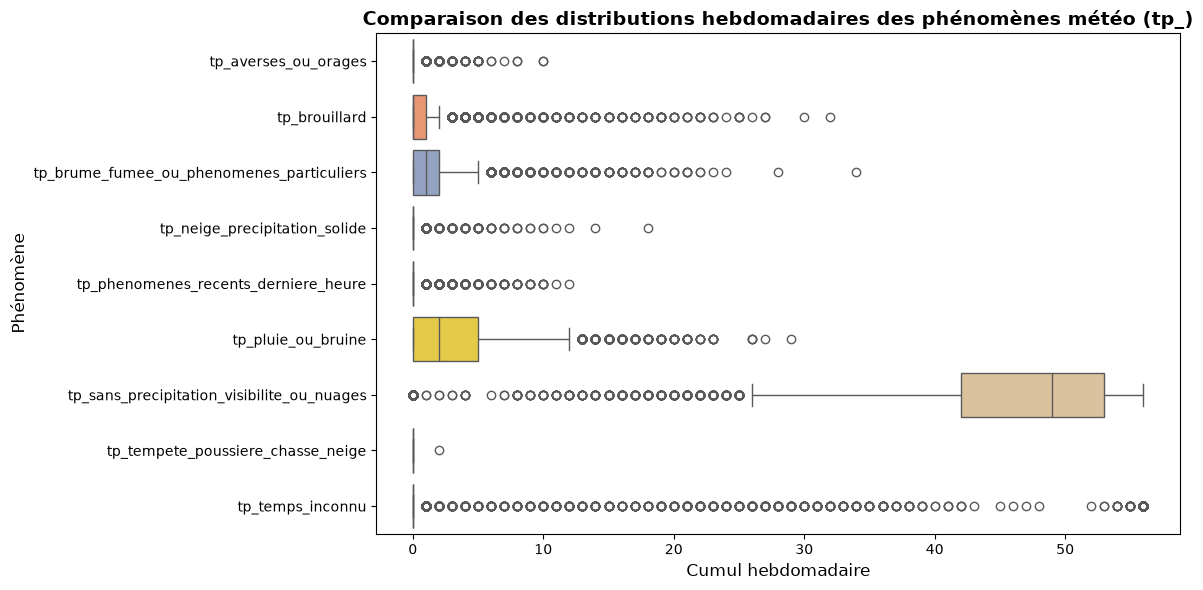

In [169]:
# 1. Sélectionner toutes les colonnes commençant par 'tp_'
cols_tp = [col for col in df_meteo_hebdo.columns if col.startswith('tp_')]

if cols_tp:
    # 2. Transformer le DataFrame au format "long" pour Seaborn
    df_tp_melted = df_meteo_hebdo.melt(
        value_vars=cols_tp, 
        var_name='Phenomene', 
        value_name='Cumul_Hebdomadaire'
    )

    # 3. Création de la figure unique
    plt.figure(figsize=(12, max(6, len(cols_tp) * 0.5)))
    sns.boxplot(
        data=df_tp_melted, 
        x='Cumul_Hebdomadaire', 
        y='Phenomene', 
        palette='Set2'
    )
    
    plt.title("Comparaison des distributions hebdomadaires des phénomènes météo (tp_)", fontsize=14, fontweight='bold')
    plt.xlabel("Cumul hebdomadaire", fontsize=12)
    plt.ylabel("Phénomène", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("Aucune colonne 'tp_' trouvée dans le DataFrame.")

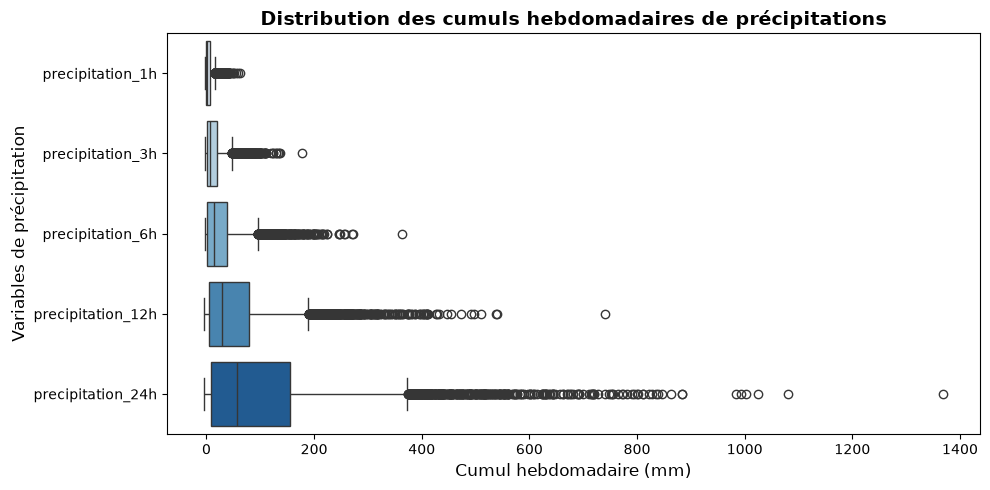

In [172]:
#précipitation
#Sélectionner toutes les colonnes commençant par 'precipitation_'
precip_cols = [col for col in df_meteo_hebdo.columns if col.startswith('precipitation_')]

if precip_cols:
    # Création du boxplot horizontal
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_meteo_hebdo[precip_cols], orient='h', palette='Blues')
    
    plt.title("Distribution des cumuls hebdomadaires de précipitations", fontsize=14, fontweight='bold')
    plt.xlabel("Cumul hebdomadaire (mm)", fontsize=12)
    plt.ylabel("Variables de précipitation", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("Aucune colonne de précipitation trouvée.")

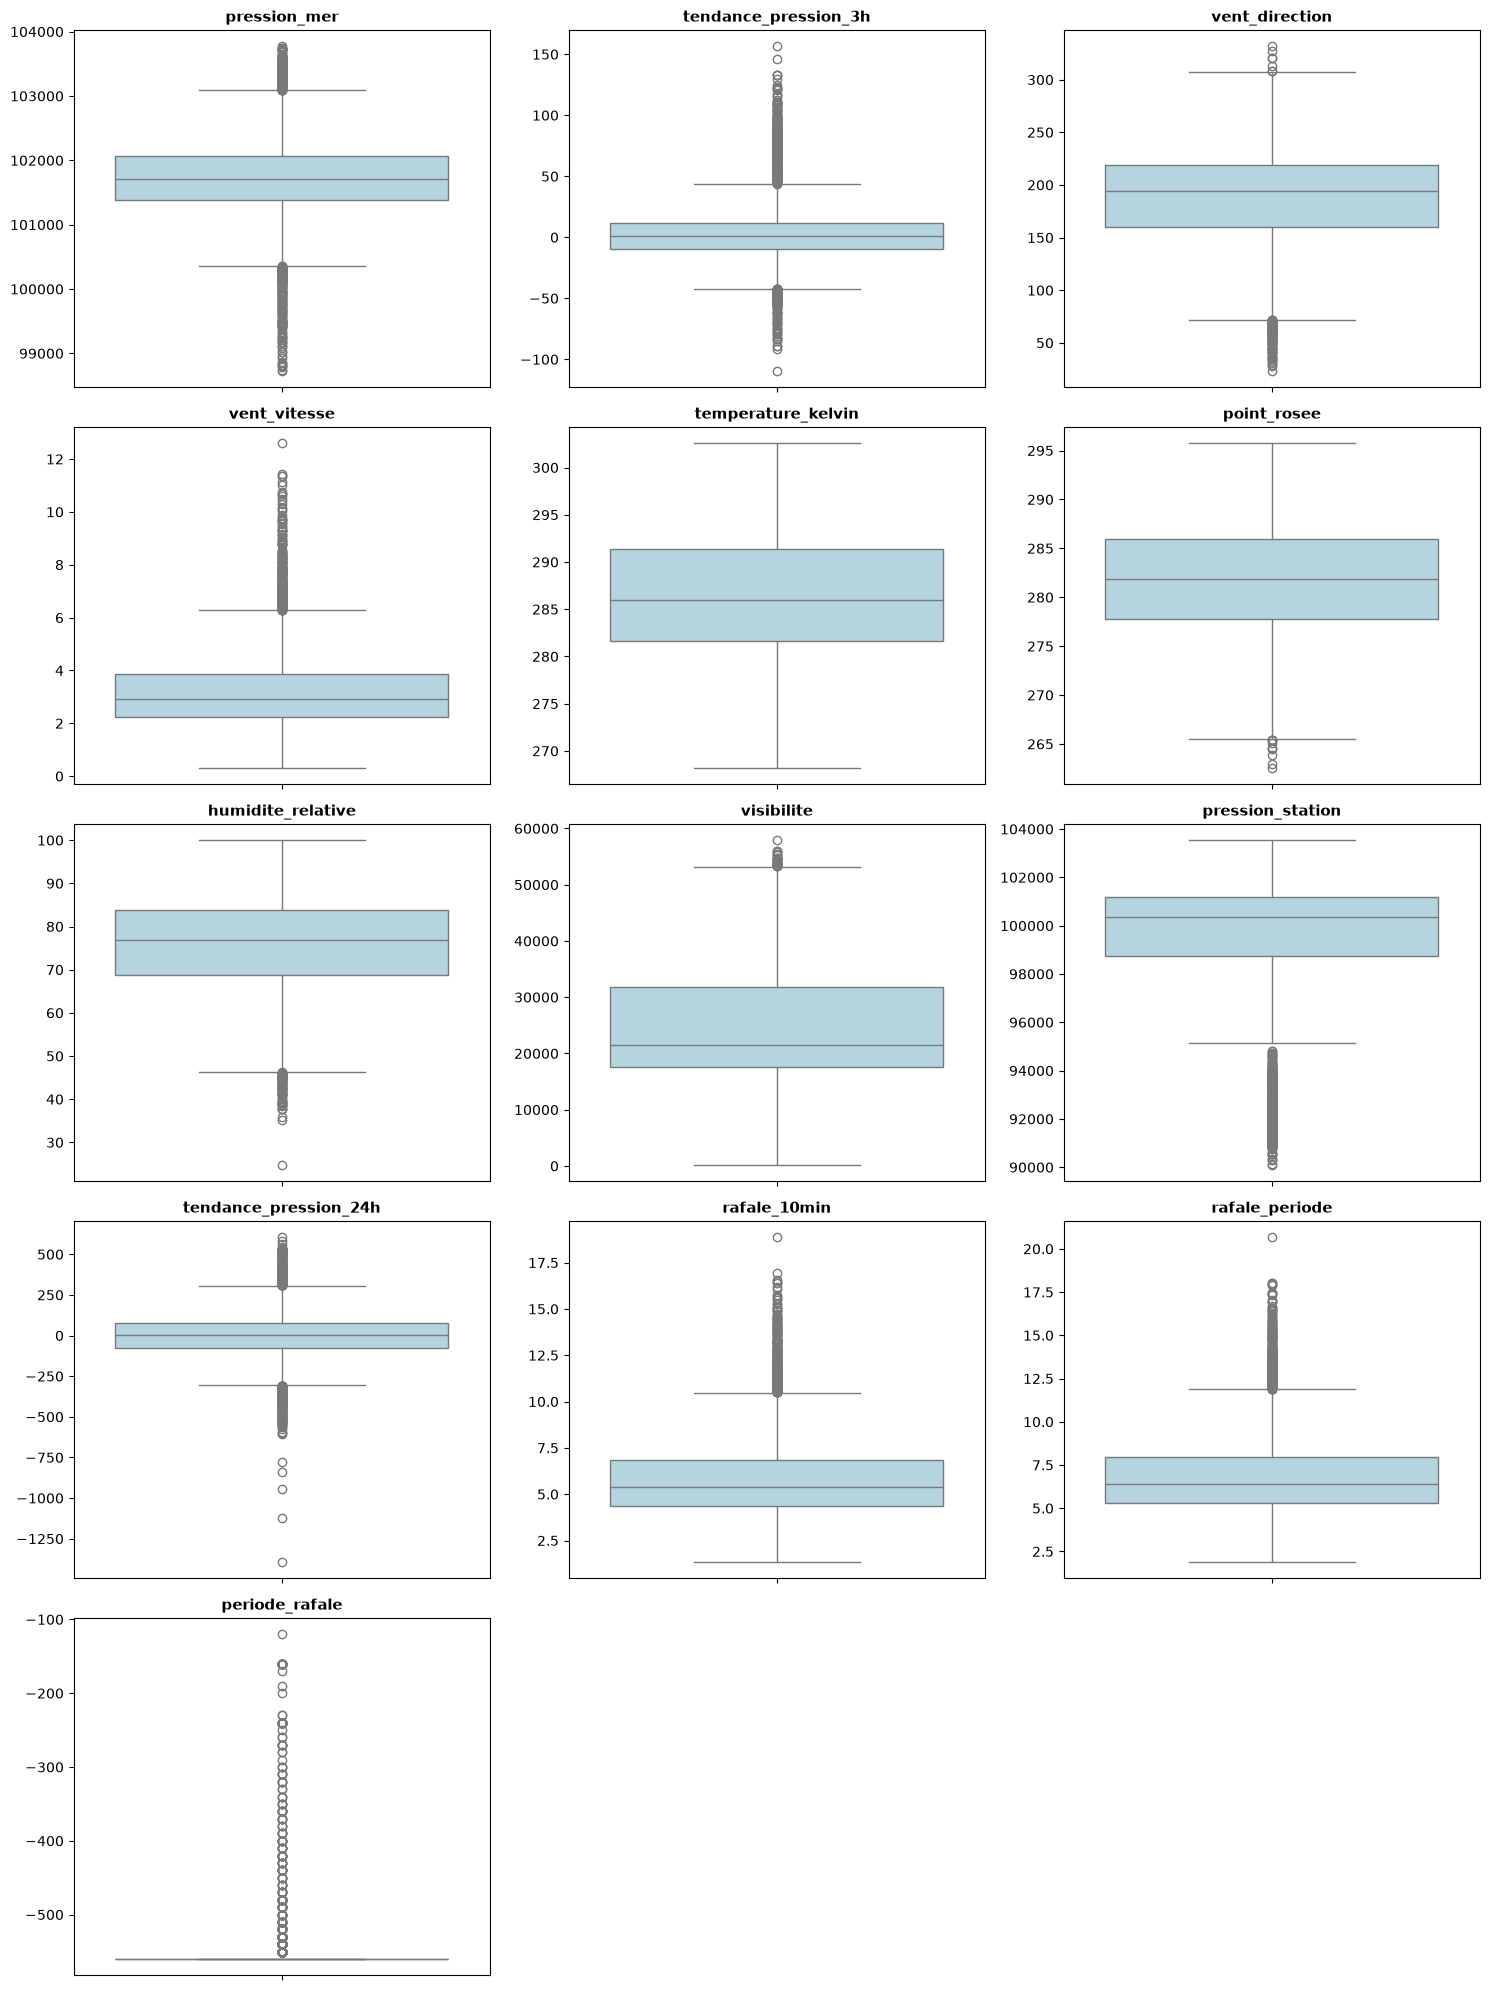

In [173]:
#reste des variables
# Liste des variables continues restantes
vars_continues = [
    'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse',
    'temperature_kelvin', 'point_rosee', 'humidite_relative', 'visibilite',
    'pression_station', 'tendance_pression_24h', 'rafale_10min',
    'rafale_periode', 'periode_rafale'
]

# Filtrer les colonnes présentes dans le DataFrame
vars_existantes = [col for col in vars_continues if col in df_meteo_hebdo.columns]

# Création d'une grille propre (3 colonnes par ligne)
n_cols = 3
n_rows = (len(vars_existantes) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(vars_existantes):
    sns.boxplot(data=df_meteo_hebdo, y=col, ax=axes[i], color='lightblue')
    axes[i].set_title(f"{col}", fontsize=11, fontweight='bold')
    axes[i].set_ylabel("")

# Suppression des sous-graphiques vides s'il y en a
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

10. représente que 40 départements sur 96 sont présents dans le dataset final. 
Pour couvrir l'ensemble des départements métropolitains à partir des 40 départements disposant de stations, la méthode la plus rigoureuse et rapide consiste à faire une imputation par le voisin le plus proche (Nearest Neighbor) en se basant sur les coordonnées géographiques (centroïdes) des départements.